<a href="https://colab.research.google.com/github/ryanaxiom/Applied-ML/blob/main/code/Day18_Carnegie.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Student Instructions**: Before you begin, click **File > Save a copy in Drive** so you do not lose your work!

In [ ]:
url = ("https://raw.githubusercontent.com/ryanaxiom/"
       "Applied-ML/main/data/carnegie_data.csv")

import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import confusion_matrix
carnegie_raw = pd.read_csv(url, encoding="cp1252")
carnegie = carnegie_raw.copy()
carnegie["research"] = carnegie["serd"] + carnegie["nonserd"]
d = carnegie[carnegie["research"].notna()].copy()
d["med_yn"] = (d["medical"] == 1).astype(int)
y = d["research"]
def rmse(a, b): return np.sqrt(np.mean((a - b)**2))
kf = KFold(n_splits=5, shuffle=True, random_state=309)
carnegie["med_yn"] = (carnegie["medical"] == 1).astype(int)
yn = carnegie["med_yn"]            # Unit 4's target: all 3,939 rows
carnegie.shape, int(yn.sum())

((3939, 103), 199)

In [ ]:
one = LogisticRegression(C=np.inf)   # C = 1/alpha: no penalty
one.fit(carnegie[["fallenr20"]], yn)
b0, b1 = one.intercept_[0], one.coef_[0][0]
b1k = 1000 * b1                      # slope per 1,000 students
print(round(b0, 4), round(b1k, 4), round(np.exp(b1k), 3))
schools = {"West Virginia University": "WVU",
           "Marshall University": "Marshall",
           "Johns Hopkins University": "JHU",
           "Massachusetts Institute of Technology": "MIT"}
for name, short in schools.items():
    row = carnegie[carnegie["name"] == name]
    p = one.predict_proba(row[["fallenr20"]])[0, 1]
    print(short, int(row["fallenr20"].iloc[0]), round(p, 4))

-3.5723 0.0761 1.079
WVU 26269 0.1719
Marshall 11958 0.0653
JHU 28890 0.2022
MIT 11254 0.0621


In [ ]:
print(round(1 / (1 + np.exp(-b0)), 4))

0.0273


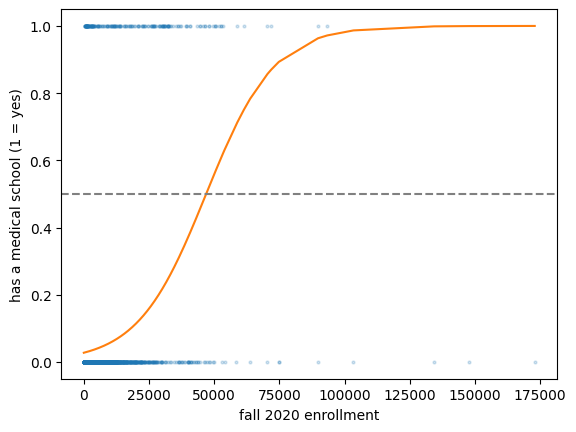

46922 33


In [ ]:
import matplotlib.pyplot as plt
x = carnegie["fallenr20"]
xs = carnegie[["fallenr20"]].sort_values("fallenr20")  # sort x
plt.scatter(x, yn, s=4, alpha=0.2)
plt.plot(xs["fallenr20"], one.predict_proba(xs)[:, 1], color="C1")
plt.axhline(0.5, linestyle="--", color="gray")
plt.xlabel("fall 2020 enrollment")
plt.ylabel("has a medical school (1 = yes)")
plt.show()
print(round(-b0 / b1), int((x > -b0 / b1).sum()))

In [ ]:
pred = cross_val_predict(one, carnegie[["fallenr20"]], yn, cv=kf)
print("model:", round((pred == yn).mean(), 4),
      " always no:", round((yn == 0).mean(), 4))
print(confusion_matrix(yn, pred))

model: 0.9487  always no: 0.9495
[[3722   18]
 [ 184   15]]


In [ ]:
print(int(pred.sum()), int((pred != yn).sum()), int((yn != 0).sum()))

33 202 199


In [ ]:
cols = ["fallenr20", "grtenr20", "docrsdeg", "totdeg", "rooms"]
five = LogisticRegression(C=np.inf)
pred = cross_val_predict(five, carnegie[cols], yn, cv=kf)
cm = confusion_matrix(yn, pred)
print(cm, round((pred == yn).mean(), 4))
tn, fp, fn, tp = cm.ravel()
print("found", tp, "of", tp + fn, "; alarms", fp, "of", tn + fp)
print(round(tp / (tp + fn), 3), round(fp / (fp + tn), 4),
      round(tp / (tp + fp), 3))

[[3715   25]
 [ 138   61]] 0.9586
found 61 of 199 ; alarms 25 of 3740
0.307 0.0067 0.709


In [ ]:
prob = cross_val_predict(five, carnegie[cols], yn, cv=kf,
                         method="predict_proba")[:, 1]
for t in [0.5, 0.3, 0.2, 0.1, 0.05]:
    pred_t = (prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(yn, pred_t).ravel()
    print(t, tp, fp, round((pred_t == yn).mean(), 4))

0.5 61 25 0.9586
0.3 75 40 0.9584
0.2 88 60 0.9566
0.1 115 123 0.9474
0.05 154 310 0.9099


In [ ]:
for name, short in schools.items():
    i = carnegie.index[carnegie["name"] == name][0]
    print(short, int(yn[i]), round(prob[i], 4))

WVU 1 0.2509
Marshall 1 0.0709
JHU 1 0.9915
MIT 0 0.8523


In [ ]:
from sklearn.model_selection import cross_val_score
naive = []
for train, test in kf.split(carnegie):
    rate = yn.iloc[train].mean()      # Day 2's naive model, yes/no
    p_hat = np.full(len(test), rate)
    y_t = yn.iloc[test]
    naive.append(-np.mean(y_t * np.log(p_hat)
                          + (1 - y_t) * np.log(1 - p_hat)))
print("naive", round(np.mean(naive), 4))
for name, est, X in [("one", one, carnegie[["fallenr20"]]),
                     ("five", five, carnegie[cols])]:
    folds = cross_val_score(est, X, yn, cv=kf,
                            scoring="neg_log_loss")
    print(name, round(-folds.mean(), 4))

naive 0.2001
one 0.1728
five 0.1455


In [ ]:
ll = {}
for name, est, X in [("one", one, carnegie[["fallenr20"]]),
                     ("five", five, carnegie[cols])]:
    folds = cross_val_score(est, X, yn, cv=kf, scoring="neg_log_loss")
    ll[name] = -folds.mean()
base = np.mean(naive)
print({k: f"{100 * (base - v) / base:.1f}%" for k, v in ll.items()})

{'one': '13.6%', 'five': '27.3%'}


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
for name, est in [("no penalty", LogisticRegression(C=np.inf)),
                  ("default C=1", LogisticRegression())]:
    pipe = make_pipeline(StandardScaler(), est)
    folds = cross_val_score(pipe, carnegie[cols], yn, cv=kf,
                            scoring="neg_log_loss")
    pred = cross_val_predict(pipe, carnegie[cols], yn, cv=kf)
    print(name, round(-folds.mean(), 4),
          round((pred == yn).mean(), 4))

no penalty 0.1456 0.9589
default C=1 0.1449 0.9589


In [ ]:
print(round(len(carnegie) / len(cols), 1), round(0.1456 - 0.1449, 4))

787.8 0.0007


In [ ]:
# codebook: 25 = "Special Focus Four-Year: Medical Schools & Ctrs"
special = (carnegie["basic2021"] == 25)
print(pd.crosstab(special, yn))

med_yn        0    1
basic2021           
False      3740  161
True          0   38


In [ ]:
rows = []
for t in np.linspace(0.02, 0.9, 20):
    pred_t = (prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(yn, pred_t).ravel()
    rows.append([round(t, 2), tp, fp, round(tp / (tp + fn), 3),
                 round(fp / (fp + tn), 4), round(tp / max(tp + fp, 1), 3)])
print(pd.DataFrame(rows, columns=["threshold", "TP", "FP", "sensitivity",
                                   "false_alarm", "precision"]).to_string(index=False))

 threshold  TP   FP  sensitivity  false_alarm  precision
      0.02 198 2688        0.995       0.7187      0.069
      0.07 136  200        0.683       0.0535      0.405
      0.11 111  103        0.558       0.0275      0.519
      0.16 100   77        0.503       0.0206      0.565
      0.21  87   59        0.437       0.0158      0.596
      0.25  80   47        0.402       0.0126      0.630
      0.30  75   40        0.377       0.0107      0.652
      0.34  71   35        0.357       0.0094      0.670
      0.39  67   32        0.337       0.0086      0.677
      0.44  66   28        0.332       0.0075      0.702
      0.48  63   25        0.317       0.0067      0.716
      0.53  57   24        0.286       0.0064      0.704
      0.58  52   22        0.261       0.0059      0.703
      0.62  48   19        0.241       0.0051      0.716
      0.67  45   17        0.226       0.0045      0.726
      0.71  43   15        0.216       0.0040      0.741
      0.76  42   15        0.21